In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
movies_df = pd.read_csv("ml-latest-small/movies.csv", index_col=0)
ratings_df = pd.read_csv("ml-latest-small/ratings.csv", index_col=0)
tags_df = pd.read_csv("ml-latest-small/tags.csv", index_col=0)

In [3]:
print(movies_df.head())
print(ratings_df.head())
print(tags_df.head())

                                      title  \
movieId                                       
1                          Toy Story (1995)   
2                            Jumanji (1995)   
3                   Grumpier Old Men (1995)   
4                  Waiting to Exhale (1995)   
5        Father of the Bride Part II (1995)   

                                              genres  
movieId                                               
1        Adventure|Animation|Children|Comedy|Fantasy  
2                         Adventure|Children|Fantasy  
3                                     Comedy|Romance  
4                               Comedy|Drama|Romance  
5                                             Comedy  
        movieId  rating  timestamp
userId                            
1             1     4.0  964982703
1             3     4.0  964981247
1             6     4.0  964982224
1            47     5.0  964983815
1            50     5.0  964982931
        movieId              tag   times

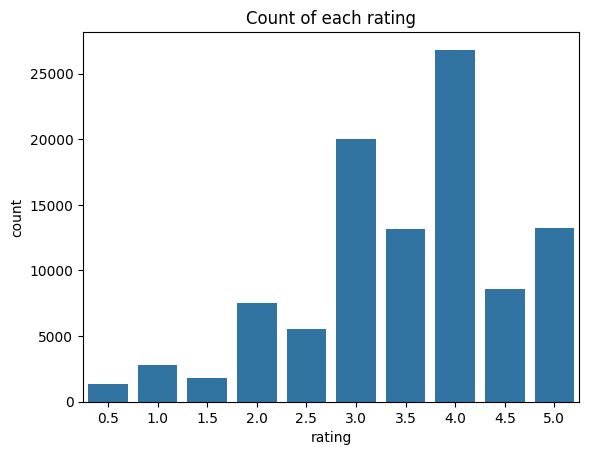

In [4]:
# ratings_df.rating.hist()  #distribution of ratings

sns.countplot(ratings_df, x="rating")
plt.title("Count of each rating")
plt.show()

In [5]:
print(ratings_df.rating.mean(), ratings_df.rating.std()) #ratings mean and standard deviation

3.501556983616962 1.042529239060635


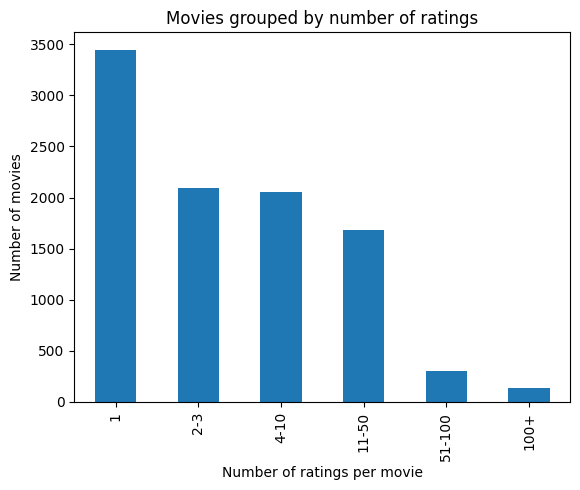

In [6]:
movie_ratings_counts = ratings_df.groupby("movieId")["rating"].count().sort_values(ascending=False) #how many ratings does each movie have

bins = [0, 1, 3, 10, 50, 100, movie_ratings_counts.max()]
labels = ["1", "2-3", "4-10", "11-50", "51-100", "100+"]

movie_bins = pd.cut(movie_ratings_counts, bins=bins, labels=labels)

distribution = movie_bins.value_counts()

distribution.plot(kind="bar")
plt.xlabel("Number of ratings per movie")
plt.ylabel("Number of movies")
plt.title("Movies grouped by number of ratings")
plt.show()


In [7]:
ratings_per_movie_mean = ratings_df.groupby("movieId")["rating"].count().mean()
ratings_per_movie_std = ratings_df.groupby("movieId")["rating"].count().std()

print(ratings_per_movie_mean, ratings_per_movie_std)

10.369806663924312 22.401004809609617


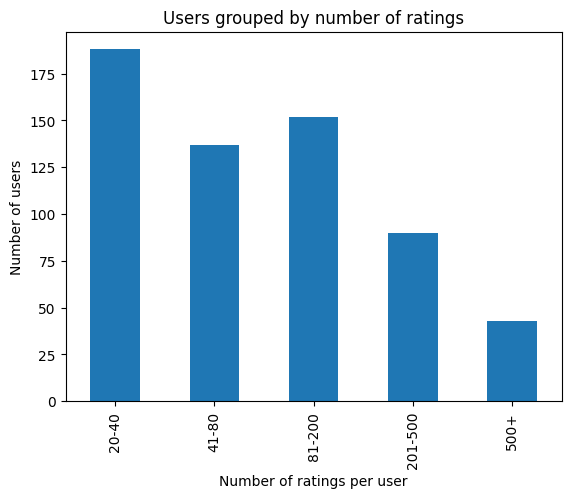

In [8]:
ratings_per_user = ratings_df.groupby("userId")["movieId"].count().sort_values(ascending=False) #how many ratings did each user provide

bins = [19, 40, 80, 200, 500, ratings_per_user.max()]

labels = ["20-40", "41-80", "81-200", "201-500", "500+"]

user_bins = pd.cut(ratings_per_user, bins=bins, labels=labels)

distribution = user_bins.value_counts().sort_index()

distribution.plot(kind="bar")
plt.xlabel("Number of ratings per user")
plt.ylabel("Number of users")
plt.title("Users grouped by number of ratings")
plt.show()


In [9]:
ratings_per_user_mean = ratings_df.groupby("userId")["movieId"].count().mean()
ratings_per_user_std = ratings_df.groupby("userId")["movieId"].count().std()

print(ratings_per_user_mean, ratings_per_user_std)

165.30491803278687 269.480584387172


In [10]:
def imdb_rating(rating_count, average_rating, threshold):
    return rating_count / (rating_count + threshold) * average_rating + threshold / (rating_count + threshold) * ratings_df.rating.mean()

In [11]:
movies_df_reset = movies_df.reset_index()  # movieId becomes a column

ratings_merged = ratings_df.merge(movies_df_reset[["movieId", "title"]], on="movieId") #merge ratings_df with title of the movies_df

movie_stats = ratings_merged.groupby("title")["rating"].agg(["count", "mean"]) #apply count and mean and create columns with same names

threshold = movie_stats["count"].quantile(0.50) #take 50% of movies with the most ratings

movie_stats["imdb_rating"] = imdb_rating(rating_count=movie_stats["count"], average_rating=movie_stats["mean"], threshold=threshold)

print(movie_stats.sort_values(by="imdb_rating", ascending=True).head()) #5 worst imdb rated movies
print(movie_stats.sort_values(by="imdb_rating", ascending=False).head()) #5 best imdb rated movies

                                          count      mean  imdb_rating
title                                                                 
Police Academy: Mission to Moscow (1994)      5  0.800000     1.813084
Jason X (2002)                                8  1.187500     1.818606
Spice World (1997)                           10  1.350000     1.846513
Speed 2: Cruise Control (1997)               19  1.605263     1.863849
Catwoman (2004)                               9  1.333333     1.875389
                                                  count      mean  imdb_rating
title                                                                         
Shawshank Redemption, The (1994)                    317  4.429022     4.420327
Three Billboards Outside Ebbing, Missouri (2017)      8  4.750000     4.409516
Trial, The (Procès, Le) (1962)                        5  4.900000     4.375584
Secrets & Lies (1996)                                11  4.590909     4.357476
Streetcar Named Desire, A (19

In [12]:
# ratings_merged = ratings_df.merge(movies_df, on="movieId") #merge dataframes to get titles and ratings

# rating_counts = ratings_merged.groupby("title")["rating"].count() #how many ratings does each movie have
# avg_rating = ratings_merged.groupby("title")["rating"].mean() #average rating of each movie

# threshold = movie_stats["count"].quantile(0.50) #take 50% of movies with the most ratings
# print(threshold)

# movies_with_enough_ratings = rating_counts[rating_counts >= threshold].index #get id of movie with more than 3 ratings

# best_rated_movies = ratings_merged.groupby("title")["rating"].mean().loc[movies_with_enough_ratings].sort_values(ascending=False)

# best_rated_movies.head(10) #show 10 best graded movies with at least 3 ratings

In [13]:
# ratings_merged = ratings_df.merge(movies_df, on="movieId") #merge dataframes to get titles and ratings

# rating_counts = ratings_merged.groupby("title")["rating"].count() #how many ratings does each movie have

# threshold = 3 #at least 3 ratings to be considered for best rated movie

# movies_with_enough_ratings = rating_counts[rating_counts >= threshold].index #get id of movie with more than 3 ratings

# best_rated_movies = ratings_merged.groupby("title")["rating"].mean().loc[movies_with_enough_ratings].sort_values(ascending=False)

# best_rated_movies.head(10) #show 10 best graded movies with at least 3 ratings

In [14]:
def group_by_year_and_plot(df, is_rating):    
    df["year"] = pd.to_datetime(df["timestamp"], utc=True, unit="s").dt.year #covert timestamp to year, units as seconds

    dates = df.groupby("year")["movieId"].count().sort_values() #how many ratings or tags at each year
    
    print(df.year.min()) #year of first rating or tag
    print(df.year.max()) #year of last rating or tag

    bins = [1995, 2000, 2005, 2010, 2015, df.year.max()]

    labels = ["1996-2000", "2001-2005", "2006-2010", "2011-2015", "2015+"]

    year_bins = pd.cut(dates.index, bins=bins, labels=labels) #assign to bins using years

    distribution = dates.groupby(year_bins, observed=True).sum() #observed to true so only bins with data are summed

    distribution.plot(kind="bar")
    
    plt.xlabel(f"Years of movies {"ratings" if is_rating else "tags"}")
    plt.ylabel(f"Number of movies {"rated" if is_rating else "tagged"}")
    plt.title(f"Movies {"ratings" if is_rating else "tags"} grouped by years")
    plt.show()

1996
2018


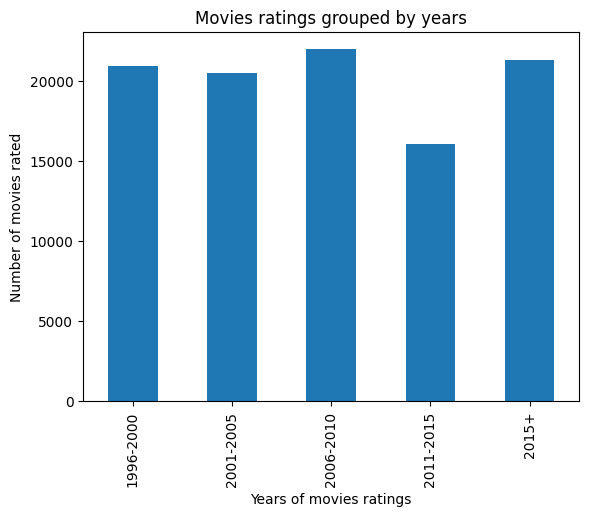

In [15]:
group_by_year_and_plot(ratings_df, is_rating=True)

2006
2018


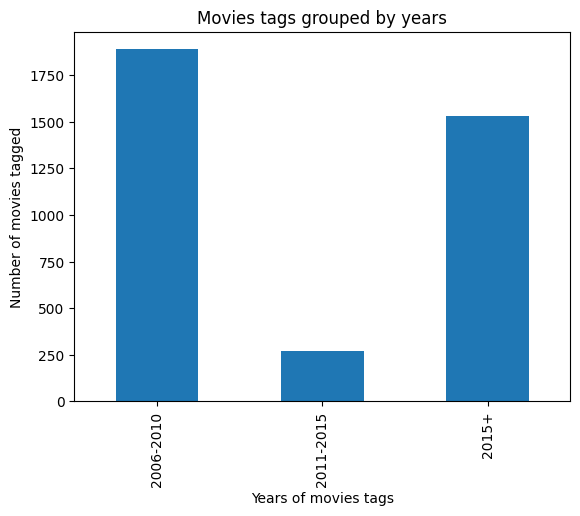

In [16]:
group_by_year_and_plot(tags_df, is_rating=False)